# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [2]:
ROLL_NO = 1024170393
NAME = "Rishabh Dutt"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [3]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [4]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {
        "sentences": sentences,
        "tokens": tokens,
        "punct": punct,
        "stops": stops,
        "final": final
    }

In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170393   Name: Rishabh Dutt   Fingerprint: 85978CAE   Tickets: 15

Ticket_ID                                                                                  Ticket_Text
      T01                         I was locked out of the student portal on my laptop. This is urgent.
      T02     E-mail was working yesterday before the assignment deadline. I have tried several times!
      T03                                             Lms is not working on my laptop. This is urgent.
      T04                      I was locked out of the projector after the latest update. Please help.
      T05                                                 See https://lms.thapar.edu/help for details.
      T06                             The server was working yesterday. The same problem occurs again.
      T07                                                 The VPN has stopped syncing. This is urgent.
      T08                                              The e-mail has stopped syncing. This 

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:
import pandas as pd

# 1. Gather stats for all tickets
stats_list = []
for idx, row in df.iterrows():
    tid = row['Ticket_ID']
    text = row['Ticket_Text']
    res = process_ticket(text)

    stats_list.append({
        "Ticket_ID": tid,
        "Sentences": len(res['sentences']),
        "Tokens": len(res['tokens']),
        "Punctuation": len(res['punct']),
        "Stopwords": len(res['stops']),
        "Unique_Tokens": len(set(res['tokens'])),
        "Final_Tokens": len(res['final'])
    })

# 2. Convert to DataFrame and add a TOTAL row
stats_df = pd.DataFrame(stats_list)
total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": stats_df["Sentences"].sum(),
    "Tokens": stats_df["Tokens"].sum(),
    "Punctuation": stats_df["Punctuation"].sum(),
    "Stopwords": stats_df["Stopwords"].sum(),
    "Unique_Tokens": stats_df["Unique_Tokens"].sum(),
    "Final_Tokens": stats_df["Final_Tokens"].sum()
}
stats_df = pd.concat([stats_df, pd.DataFrame([total_row])], ignore_index=True)

print("=== PREPROCESSING STATS TABLE ===")
display(stats_df)


=== PREPROCESSING STATS TABLE ===


,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique_Tokens,Final_Tokens
0,T01,2,16,2,9,15,5
1,T02,2,15,2,5,15,8
2,T03,2,12,2,6,10,4
3,T04,2,15,2,7,13,6
4,T05,1,7,2,1,7,4
5,T06,2,12,2,5,10,5
6,T07,2,10,2,4,9,4
7,T08,2,10,2,4,9,4
8,T09,2,14,2,5,13,7
9,T10,1,7,2,1,7,4


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]
import re

# Join all raw ticket texts into one string for demonstration
all_tickets_text = " ".join(df["Ticket_Text"].tolist())

# --- EXTRACTION TESTS (on TEST_LINES) ---
print("=== EXTRACTION ON TEST LINES ===")
for i, line in enumerate(TEST_LINES):
    print(f"\nLine {i+1}: {line}")
    print("Words > 5 chars:  ", re.findall(r'\b[a-zA-Z]{6,}\b', line))
    print("Numbers (dec/ver):", re.findall(r'\b\d+(?:\.\d+)*\b', line))
    print("Capitalized words:", re.findall(r'\b[A-Z][a-zA-Z]*\b', line))
    print("Vowel-start words:", re.findall(r'\b[aeiouAEIOU][a-zA-Z]*\b', line))

# --- REPLACEMENT TESTS (on TEST_LINES) ---
print("\n=== REPLACEMENT ON TEST LINES ===")
email_pattern = r'\b[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}\b'
url_pattern = r'\b(?:https?://|www\.)\S+\b'
phone_pattern = r'\+?\d{1,4}[-\s]?\d{3,5}[-\s]?\d{4}'

for i, line in enumerate(TEST_LINES):
    temp = re.sub(email_pattern, '<EMAIL>', line)
    temp = re.sub(url_pattern, '<URL>', temp)
    cleaned_line = re.sub(phone_pattern, '<PHONE>', temp)
    print(f"\nOriginal: {line}")
    print(f"Cleaned:  {cleaned_line}")

=== EXTRACTION ON TEST LINES ===

Line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Words > 5 chars:   ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers (dec/ver): []
Capitalized words: ['Mail']
Vowel-start words: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']

Line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Words > 5 chars:   ['Version']
Numbers (dec/ver): ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
Capitalized words: ['Call', 'Version', 'Rs']
Vowel-start words: ['or', 'is']

Line 3: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Words > 5 chars:   []
Numbers (dec/ver): ['5.30']
Capitalized words: ['The']
Vowel-start words: ['of', 'art', 'isn', 'open', 'in', 'at']

=== REPLACEMENT ON TEST LINES ===

Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.a

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [11]:
# Your code
pattern = r'''(?x)                # Flag to allow comments and ignore whitespace
    (?:https?://|www\.)\S+        # URLs
    |\b[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}\b  # Emails
    |\+?\d{1,4}[-\s]?\d{3,5}[-\s]?\d{4} # Phone numbers
    |\b\d+(?:\.\d+)+\b            # Decimals and Version numbers (95.5, 2.0.1)
    |\b[a-zA-Z]+(?:-[a-zA-Z]+)+\b  # Hyphenated words (Wi-Fi, state-of-the-art)
    |\b[a-zA-Z]+'(?:s|t|re|ve|m|ll|d)\b # Contractions (isn't, didn't, can't)
    |\b\w+\b                      # Regular words
'''
from nltk.tokenize import RegexpTokenizer, word_tokenize
def my_tokenize(text):
    tokenizer = RegexpTokenizer(pattern)
    return tokenizer.tokenize(text)

# --- Test on TEST_LINES ---
print("=== CUSTOM TOKENIZATION ON TEST LINES ===")
for i, line in enumerate(TEST_LINES):
    print(f"\nLine {i+1}: {line}")
    print("my_tokenize:   ", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))


=== CUSTOM TOKENIZATION ON TEST LINES ===

Line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize:    ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize:    ['Call', '+91 98765 4321', '+91-98765-4321', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Line 3: The state-of-the-art lab isn't open; log-in at 5.30 p.m. di

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [15]:
import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet
import pandas as pd

# 1. Collect all unique final tokens from our dataset
unique_final_tokens = set()
for idx, row in df.iterrows():
    res = process_ticket(row['Ticket_Text'])
    unique_final_tokens.update(res['final'])

unique_final_tokens = sorted(list(unique_final_tokens))
print(f"Total unique final tokens found: {len(unique_final_tokens)}")
print("Sample final tokens:", unique_final_tokens[:15])


Total unique final tokens found: 61
Sample final tokens: ['//lms.thapar.edu/help', '2.0.1', '99', 'another', 'anything', 'asap', 'asking', 'assignment', 'ca', 'change', 'computer', 'connect', 'could', 'crashes', 'deadline']


### RegexpStemmer Suffix Choice and Justification
Looking at our final tokens, we frequently see suffixes like `'ing'` (in words like *working*, *disconnecting*, *syncing*) and `'ed'` (in words like *locked*, *tried*, *restarted*).
We will use a standard `RegexpStemmer` with a rule to strip the suffix `'ing$'` or `'ed$'` (or both) and justify this based on these words.

In [13]:
# 2. Helper function to map NLTK POS tags to WordNet POS tags
def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

# Initialize the stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()
# Strip suffix 'ing' or 'ed' with a minimum length constraint
regexp_stemmer = RegexpStemmer('ing$|ed$', min=4)
lemmatizer = WordNetLemmatizer()

# Get POS tags for all unique final tokens
pos_tags = nltk.pos_tag(unique_final_tokens)

# 3. Perform comparison
comparison_rows = []
for word, tag in pos_tags:
    p_stem = porter.stem(word)
    l_stem = lancaster.stem(word)
    r_stem = regexp_stemmer.stem(word)

    wn_pos = get_wordnet_pos(tag)
    lemmed = lemmatizer.lemmatize(word, pos=wn_pos)

    # Check if any of the outputs differ
    outputs = {p_stem, l_stem, r_stem, lemmed}
    if len(outputs) > 1:
        comparison_rows.append({
            "Original_Word": word,
            "POS_Tag": tag,
            "Porter": p_stem,
            "Lancaster": l_stem,
            "RegexpStemmer": r_stem,
            "WordNetLemmatizer": lemmed
        })

# Convert to DataFrame and display
comparison_df = pd.DataFrame(comparison_rows)
print(f"\nWords where outputs differ (showing first 30 rows of {len(comparison_df)}):")
display(comparison_df.head(30))


Words where outputs differ (showing first 30 rows of 35):


,Original_Word,POS_Tag,Porter,Lancaster,RegexpStemmer,WordNetLemmatizer
0,another,DT,anoth,anoth,another,another
1,anything,NN,anyth,anyth,anyth,anything
2,assignment,NN,assign,assign,assignment,assignment
3,change,VB,chang,chang,change,change
4,computer,NN,comput,comput,computer,computer
5,crashes,VB,crash,crash,crashes,crash
6,deadline,VB,deadlin,deadlin,deadline,deadline
7,details,NNS,detail,detail,details,detail
8,file,NN,file,fil,file,file
9,getting,VBG,get,get,gett,get


---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

=== CORPUS STATISTICS ===


,Corpus State,Tokens,Unique Tokens,TTR
0,S1 (All tokens),187,90,0.4813
1,S2 (No punctuation),156,84,0.5385
2,S3 (Final tokens),86,61,0.7093
3,S4 (S3 after Porter),86,58,0.6744



=== TOP 10 WORDS IN S1 ===
[('.', 23), ('the', 13), ('i', 8), ('is', 7), ('this', 5), ('urgent', 5), ('was', 4), ('yesterday', 4), ('out', 3), ('of', 3)]

=== TOP 10 WORDS IN S3 ===
[('urgent', 5), ('yesterday', 4), ('working', 3), ("n't", 3), ('locked', 2), ('laptop', 2), ('e-mail', 2), ('assignment', 2), ('deadline', 2), ('tried', 2)]

=== TOP 5 BIGRAMS IN S1 ===
[(('.', 'this'), 5), (('this', 'is'), 5), (('is', 'urgent'), 5), (('urgent', '.'), 5), (('.', 'i'), 5)]

=== TOP 5 BIGRAMS IN S3 ===
[(('laptop', 'urgent'), 2), (('urgent', 'e-mail'), 2), (('working', 'yesterday'), 2), (('assignment', 'deadline'), 2), (('tried', 'several'), 2)]


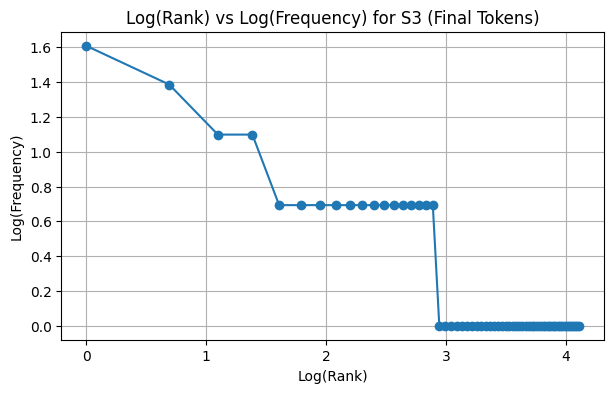

In [14]:
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
from nltk.util import ngrams

# State definitions
# S1: All tokens
S1 = [t.lower() for s in df['Ticket_Text'] for t in word_tokenize(s)]

# S2: No punctuation
S2 = [t for t in S1 if not is_punct(t)]

# S3: Final tokens (no punctuation, no stopwords)
S3 = []
for s in df['Ticket_Text']:
    S3.extend(process_ticket(s)['final'])

# S4: S3 after Porter Stemmer
porter = PorterStemmer()
S4 = [porter.stem(t) for t in S3]

# 1. Compute corpus statistics (Tokens, Unique, TTR)
stats = []
for name, tokens in [("S1 (All tokens)", S1),
                      ("S2 (No punctuation)", S2),
                      ("S3 (Final tokens)", S3),
                      ("S4 (S3 after Porter)", S4)]:
    num_tokens = len(tokens)
    num_unique = len(set(tokens))
    ttr = num_unique / num_tokens if num_tokens > 0 else 0
    stats.append({
        "Corpus State": name,
        "Tokens": num_tokens,
        "Unique Tokens": num_unique,
        "TTR": round(ttr, 4)
    })

stats_df = pd.DataFrame(stats)
print("=== CORPUS STATISTICS ===")
display(stats_df)

# 2. Print top 10 words of S1 and S3
print("\n=== TOP 10 WORDS IN S1 ===")
print(Counter(S1).most_common(10))

print("\n=== TOP 10 WORDS IN S3 ===")
print(Counter(S3).most_common(10))

# 3. Print top 5 bigrams of S1 and S3
print("\n=== TOP 5 BIGRAMS IN S1 ===")
print(Counter(ngrams(S1, 2)).most_common(5))

print("\n=== TOP 5 BIGRAMS IN S3 ===")
print(Counter(ngrams(S3, 2)).most_common(5))

# 4. Plot log(rank) vs log(frequency) for S3
counts = Counter(S3)
frequencies = sorted(list(counts.values()), reverse=True)
ranks = list(range(1, len(frequencies) + 1))

plt.figure(figsize=(7, 4))
plt.plot(np.log(ranks), np.log(frequencies), marker='o', linestyle='-')
plt.title("Log(Rank) vs Log(Frequency) for S3 (Final Tokens)")
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.grid(True)
plt.show()
